In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src.config import dados, imagens_vn
from pathlib import Path
import yaml


In [3]:
caminho_yaml = dados / "parametros.yaml"

with open(caminho_yaml, "r", encoding="utf-8") as f:
    param = yaml.safe_load(f)

for grupo in param.values():
    globals().update(grupo)

In [4]:
# Velocidade de Stall
def stall_speed(n, CL):

    return np.sqrt((2 * W * n) / (rho * S * CL))

# Curva de Stall
def n_function(V, CL):

    return (CL * rho * S * V**2) / (2 * W)

In [5]:
Vs_pos = stall_speed(nMax, CLmax)                          # Velocidade de estol máxima para o fator de carga máximo
Vs_neg = stall_speed(nMin, CLmin)                          # Velocidade de estol mínima para o fator de carga mínimo
Vs_flap = stall_speed(nMax_flap, CLmax_flap)               # Velocidade de estol mínima com os flaps acionados 


VsMin = np.sqrt((2 * W) / (rho * S * CLmax))               # Velocidade mínima da aeronave
VsMin_flap = np.sqrt((2 * W) / (rho * S * CLmax_flap))     # Velocidade mínima da aeronave com os flaps acionados

V_f = np.maximum(1.4 * VsMin, 1.8 * VsMin_flap)            # Velocidade de Projeto dos Flaps

In [6]:
display(Vs_pos, Vs_neg)

np.float64(98.53846071190736)

np.float64(73.461186984468)

In [7]:
#Vetores de velocidade para o diagrama V-n de manobras

zero_to_Vs_pos = np.linspace(0, Vs_pos, 100)
zero_to_Vs_neg = np.linspace(0, Vs_neg, 100)
zero_to_Vd = np.linspace(0, V_d, 100)
zero_to_Vc = np.linspace(0, V_c, 100)
Vs_pos_to_Vd = np.linspace(Vs_pos, V_d, 100)
Vs_neg_to_Vd = np.linspace(Vs_neg, V_d, 100)

In [8]:
# Envelope de manobras
# Curva de fator de carga positivo para o estol no diagrama V-n de manobras:
curva_n_pos = n_function(zero_to_Vs_pos, CLmax)
curva_n_pos_cte = nMax * np.ones(100)
# Curva de fator de carga negativo para o estol no diagrama V-n de manobras:
curva_n_neg = n_function(zero_to_Vs_neg, CLmin)
curva_n_neg_cte = nMin * np.ones(100)


# Curva de fator de carga com flaps defletidos:
# vetores de velocidade 
VsMin_flap_to_Vs_flap = np.linspace(0, Vs_flap, 100)
Vs_flap_to_V_f = np.linspace(Vs_flap, V_f, 100)
# Curvas
curva_n_flap = n_function(VsMin_flap_to_Vs_flap, CLmax_flap)
curva_n_flap_cte = nMax_flap * np.ones(100)

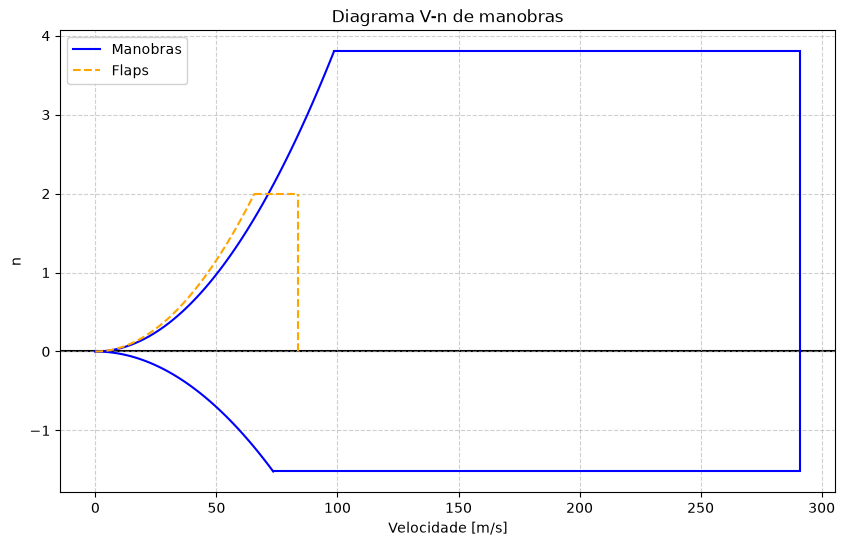

In [9]:
fig, ax = plt.subplots(figsize=(10, 6))

# Manobras
# Fatores de carga positivos
ax.plot(zero_to_Vs_pos, curva_n_pos, color='blue', label='Manobras')
ax.plot(Vs_pos_to_Vd, curva_n_pos_cte, color='blue')
# Fatores de carga negativos
ax.plot(zero_to_Vs_neg, curva_n_neg, color='blue')
ax.plot(Vs_neg_to_Vd, curva_n_neg_cte, color='blue')
#V_d
ax.vlines(V_d, nMin, nMax, color='blue')


# Flaps
ax.plot(VsMin_flap_to_Vs_flap, curva_n_flap, color='orange' , linestyle='--', label='Flaps')
ax.plot(Vs_flap_to_V_f, curva_n_flap_cte, color='orange' , linestyle='--')
# V_f
ax.vlines(V_f, 0, nMax_flap, color='orange', linestyle='--')


# Adiciona uma linha contínua e mais espessa em y = 0
ax.axhline(0, color='black', linewidth=1.5, linestyle='-', zorder=1)


# configurações do gráfico
ax.set_xlabel('Velocidade [m/s]')
ax.set_ylabel('n')
ax.set_title('Diagrama V-n de manobras')
ax.legend(loc='upper left', fontsize=10, framealpha=0.9)
ax.grid(True, linestyle="--", alpha=0.6)
plt.savefig(imagens_vn / '01.diagrama_vn_manobras.png', dpi=300)

plt.show()

In [10]:
# Diagrama V-n de rajadas

KUB = 15.24 # Velocidade efeitia de rajada em VB [m/s]
KUC = 12.19 # Velocidade efeitia de rajada em VC [m/s]
KUD = 6.10  # Velocidade efeitia de rajada em VD [m/s]

In [11]:
def rajada(K, Vpos, Vneg=None):
    delta_n = (K * rho * S * beta) / (2 * W)
    n_max = 1 + delta_n * Vpos

    if Vneg is not None:
        n_min = -delta_n * Vneg
    else:
        n_min = -delta_n * Vpos

    return delta_n, n_max, n_min



In [12]:
s = [delta_nS, nS_pos, nS_neg] = rajada(KUB,Vs_pos, Vs_neg)
c = [delta_nC, nC_pos, nC_neg] = rajada(KUC,V_c)
d = [delta_nD, nD_pos, nD_neg] = rajada(KUD,V_d)

In [13]:
# Criando as curvas de rajadas

# Rajada estol
S_pos = np.linspace(0, Vs_pos, 100) * delta_nS + 1
S_neg = - np.linspace(0, Vs_neg, 100) * delta_nS

# Rajada cruzeiro
C_pos = np.linspace(0, V_c, 100) * delta_nC + 1
C_neg = - np.linspace(0, V_c, 100) * delta_nC

# Rajada mergulho
D_pos = np.linspace(0, V_d, 100) * delta_nD + 1
D_neg = - np.linspace(0, V_d, 100) * delta_nD

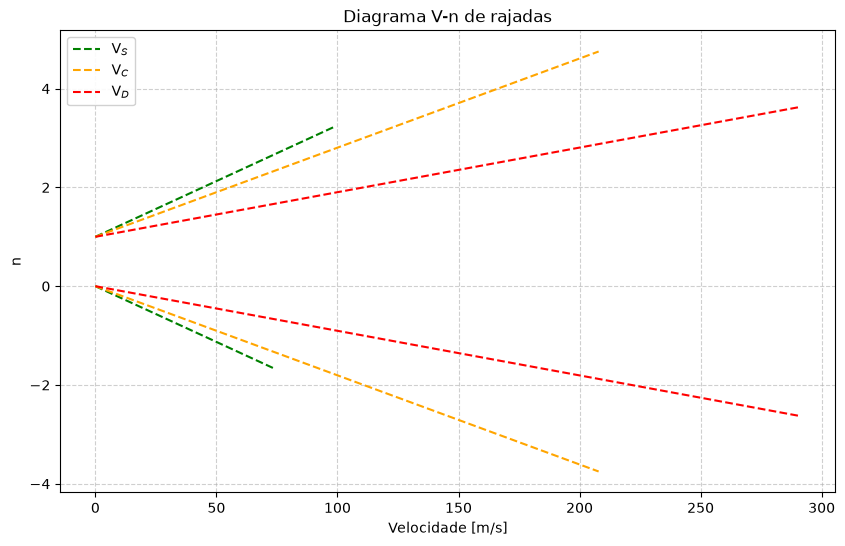

In [14]:
fig, ax = plt.subplots(figsize=(10, 6))

# Estol
ax.plot(zero_to_Vs_pos, S_pos, color='green', label='V$_{S}$', linestyle='--')
ax.plot(zero_to_Vs_neg, S_neg, color='green', linestyle='--')

# Cruzeiro
ax.plot(zero_to_Vc, C_pos, color='orange', label='V$_{C}$', linestyle='--')
ax.plot(zero_to_Vc, C_neg, color='orange', linestyle='--')

# Mergulho
ax.plot(zero_to_Vd, D_pos, color='red', label='V$_{D}$', linestyle='--')
ax.plot(zero_to_Vd, D_neg, color='red', linestyle='--')

# configurações do gráfico
ax.set_xlabel('Velocidade [m/s]')
ax.set_ylabel('n')
ax.set_title('Diagrama V-n de rajadas')
ax.legend(loc='upper left', fontsize=10, framealpha=0.9)
ax.grid(True, linestyle="--", alpha=0.6)
plt.savefig(imagens_vn / '02.diagramaVN_Rajadas.png', dpi=300, bbox_inches='tight')

plt.show()

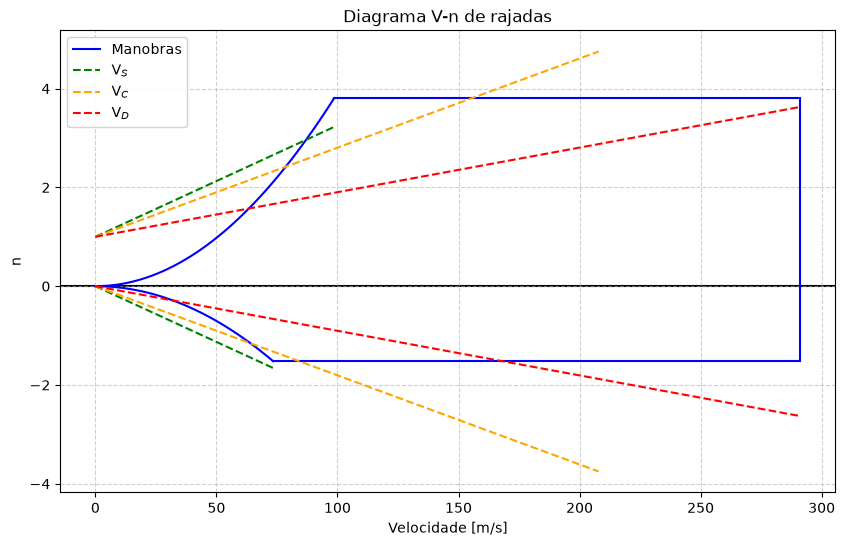

In [15]:
fig, ax = plt.subplots(figsize=(10, 6))

#==============================================================================
# Manobras
#==============================================================================

# Fatores de carga positivos
ax.plot(zero_to_Vs_pos, curva_n_pos, color='blue', label='Manobras')
ax.plot(Vs_pos_to_Vd, curva_n_pos_cte, color='blue')
# Fatores de carga negativos
ax.plot(zero_to_Vs_neg, curva_n_neg, color='blue')
ax.plot(Vs_neg_to_Vd, curva_n_neg_cte, color='blue')
#V_d
ax.vlines(V_d, nMin, nMax, color='blue')


# Flaps
#ax.plot(VsMin_flap_to_Vs_flap, curva_n_flap, color='red' , linestyle='--', label='Flaps')
#ax.plot(Vs_flap_to_V_f, curva_n_flap_cte, color='red' , linestyle='--')
# V_f
#ax.vlines(V_f, 0, nMax_flap, color='red', linestyle='--')

# Adiciona uma linha contínua e mais espessa em y = 0
ax.axhline(0, color='black', linewidth=1.5, linestyle='-', zorder=1)

#==============================================================================
# Rajadas
#==============================================================================

# Estol
ax.plot(zero_to_Vs_pos, S_pos, color='green', label='V$_{S}$', linestyle='--')
ax.plot(zero_to_Vs_neg, S_neg, color='green', linestyle='--')

# Cruzeiro
ax.plot(zero_to_Vc, C_pos, color='orange', label='V$_{C}$', linestyle='--')
ax.plot(zero_to_Vc, C_neg, color='orange', linestyle='--')

# Mergulho
ax.plot(zero_to_Vd, D_pos, color='red', label='V$_{D}$', linestyle='--')
ax.plot(zero_to_Vd, D_neg, color='red', linestyle='--')


# configurações do gráfico
ax.set_xlabel('Velocidade [m/s]')
ax.set_ylabel('n')
ax.set_title('Diagrama V-n de rajadas')
ax.legend(loc='upper left', fontsize=10, framealpha=0.9)
ax.grid(True, linestyle="--", alpha=0.6)
plt.savefig(imagens_vn / '03.diagramaVN_Rajadas2.png', dpi=300, bbox_inches='tight')

plt.show()

In [16]:
x1 = [Vs_neg, V_c, V_d]
y1 = [nMin, nC_neg, np.minimum(nD_neg, nMin)]

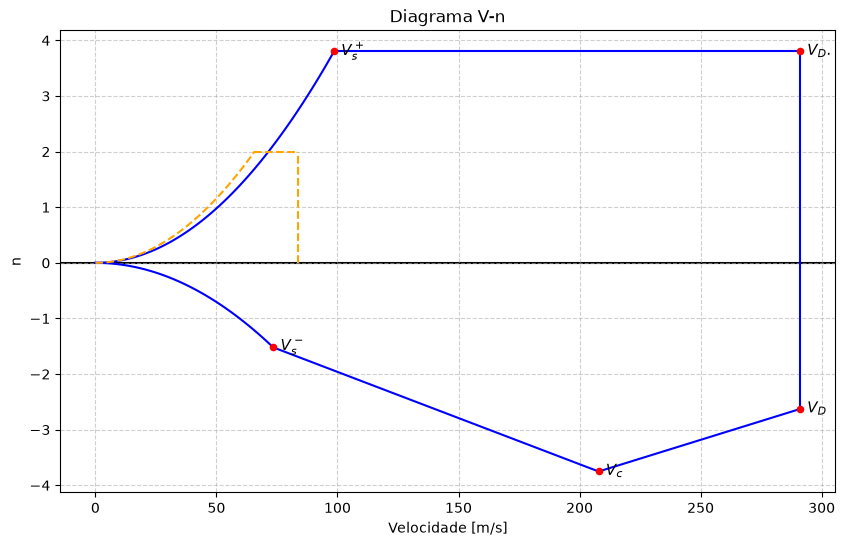

In [18]:
# Diagrama V-n final

#%matplotlib ipympl 
fig, ax = plt.subplots(figsize=(10, 6))

pontos ={
    '$V_s^+$': (Vs_pos, nMax),
    '$V_s^-$': (Vs_neg, nMin),
    '$V_c$': (V_c, nC_neg),
    '$V_D$': (V_d, np.minimum(nD_neg, nMin)),
    '$V_D.$': (V_d, nMax)
}

# Fatores de carga positivos
ax.plot(zero_to_Vs_pos, curva_n_pos, color='blue', label='Manobras')
ax.plot(Vs_pos_to_Vd, curva_n_pos_cte, color='blue')
# Fatores de carga negativos
ax.plot(zero_to_Vs_neg, curva_n_neg, color='blue')
ax.plot(x1, y1, color='blue')
#V_d
ax.vlines(V_d, nD_neg, nMax, color='blue')

# Flaps
ax.plot(VsMin_flap_to_Vs_flap, curva_n_flap, color='orange' , linestyle='--', label='Flaps')
ax.plot(Vs_flap_to_V_f, curva_n_flap_cte, color='orange' , linestyle='--')
# V_f
ax.vlines(V_f, 0, nMax_flap, color='orange', linestyle='--')

for letra, (v, n) in pontos.items():
    ax.scatter(v, n, color='red', marker='o', s=20, zorder=5)
    ax.text(v + 3, n, letra, fontsize=11, fontweight='bold', color='black', verticalalignment='center', zorder=6, horizontalalignment='left')


# configurações do gráfico
ax.axhline(0, color='black', linewidth=1.5, linestyle='-', zorder=1)
ax.set_xlabel('Velocidade [m/s]')
ax.set_ylabel('n')
ax.set_title('Diagrama V-n')
#ax.legend(loc='upper left', fontsize=10, framealpha=0.9)
ax.grid(True, linestyle="--", alpha=0.6)
plt.savefig(imagens_vn / '04.diagramaVN_final.png', dpi=300, bbox_inches='tight')

plt.show()

In [ ]:
# Pontos do diagrama V-n a serem usados para análise estrutural
xpoits = [Vs_pos, Vs_neg, V_c, V_d, V_d]
ypoints = [nMax, nMin, nC_neg, nD_neg, nMax]
display(xpoits, ypoints)

[np.float64(98.53846071190736),
 np.float64(73.461186984468),
 207.8736,
 291.02304,
 291.02304]

[3.8, -1.52, -3.751596744198301, -2.6282720422849457, 3.8]

In [ ]:
df = pd.DataFrame({'V': xpoits, 'n': ypoints})
display(df)

,V,n
0,98.538461,3.800000
1,73.461187,-1.520000
2,207.873600,-3.751597
3,291.023040,-2.628272
4,291.023040,3.800000


In [ ]:
df.to_csv(dados / 'pontos_criticos_diagramaVN.csv')